# Data Understanding

This section summarizes the meaning, business interpretation, and potential analytical or modeling use of each variable in the dataset.

| Column | Meaning | Description / Potential Use |
|---|---|---|
| `order_date` | Order Date | The date when the customer placed the order. This is one of the key time variables and can be used to derive year, month, week, day of week, seasonality, and holiday-related features. |
| `return_date` | Return Date | The date when the product was returned. Missing values are expected for non-return transactions. Can be used to create features such as `days_to_return` and return-related metrics. |
| `ship_date` | Shipping Date | The date when the product was shipped. It may be missing for cancelled, unshipped, or certain document types. Can be used to calculate `shipping_delay = ship_date - order_date`. |
| `week_begin` | Business Week Start Date | The beginning date of the business week associated with the transaction. Useful for weekly aggregation, trend analysis, and weekly pricing models. |
| `month_fiscal` | Fiscal Month | The fiscal month associated with the transaction under Lenovo's fiscal calendar. Useful for monthly trend and seasonality analysis. |
| `quarter_fiscal` | Fiscal Quarter | The fiscal quarter associated with the transaction, such as FY27Q1. Useful for analyzing quarterly trends in pricing, demand, revenue, and margin. |
| `document_type` | Transaction Document Type | Indicates the type of business transaction, such as Invoice, Order, Warranty Service, or Return. Important for distinguishing actual sales from returns, service activities, and other records. |
| `document_category` | Transaction Document Category | Provides a more detailed classification of the transaction, such as Standard Invoice, Sales Order, Return Order, Credit Memo, or Manual Adjustment. Useful for defining which records should be included in sales modeling. |
| `customer_id` | Customer Identifier | An anonymized identifier for each customer. Can be used to study customer purchase frequency, historical behavior, and customer-level price sensitivity. |
| `state` | State / Province | The state or province associated with the customer or transaction. Can capture geographic differences in demand and pricing behavior. |
| `city` | City | The city associated with the transaction. Its usefulness should be evaluated based on missingness and the number of unique values. |
| `order_status` | Order Status | Indicates the status of the transaction, such as shipped, returned, or cancelled. Important for identifying completed sales and excluding inappropriate records from demand modeling. |
| `product_id` | Product / SKU Identifier | A unique identifier for a specific product or SKU. Useful for product-level pricing analysis, although it may have high cardinality. |
| `product_name` | Product Name | The descriptive name of the product. Useful for interpretation and reporting, but may not be suitable as a direct ML feature because of high cardinality. |
| `product_line` | Product Line | A higher-level product classification. Useful for comparing pricing behavior and demand across different product lines. |
| `product_model` | Product Model | The product model or sub-series associated with the transaction. This may become an important aggregation level for price sensitivity analysis. |
| `accessory_category` | Accessory / Product Category | A category describing the accessory or detailed product group. Some products may not have an accessory category, so missing values can be expected. |
| `segment` | Customer / Business Segment | Represents the market or customer segment, such as Personal, Enterprise, or Partner Channel. A key feature because price sensitivity can differ substantially across customer segments. |
| `product_type` | Product Type | A broad product category such as Notebook, Desktop, Workstation, Tablet, Option, Server, Phone, or Service. Useful for controlling for major differences in product characteristics and price levels. |
| `country` | Country | The country associated with the transaction. Useful for capturing geographic, currency, market, and demand differences. |
| `sales_channel` | Sales Channel | The channel through which the product was sold, such as Direct, Marketplace, Clearance, Employee Program, or Partner Program. A key contextual variable because pricing strategies may differ significantly by channel. |
| `order_units` | Ordered Units | The number of units included in the order. Can be used as a demand or volume measure after filtering for valid sales transactions. |
| `revenue` | Revenue | The revenue associated with the transaction. One of the main business outcome variables. Can also be used with units to construct an estimated unit price. |
| `invoice_quantity` | Invoice Quantity | The number of units recorded on the invoice. It may differ from `order_units` and can represent the quantity actually invoiced. |
| `invoice_revenue_country_currency` | Invoice Revenue in Local Currency | The invoiced revenue expressed in the transaction country's currency. Useful for financial reconciliation and country-level revenue analysis. |
| `tax` | Tax Amount | The tax amount associated with the transaction. May be missing or zero depending on transaction type and tax treatment. Usually more relevant for financial reporting than price sensitivity modeling. |
| `cost` | Cost | The cost associated with the transaction. The sign convention should be validated before calculating profitability metrics. |
| `margin` | Margin | The transaction-level margin or profit contribution. This is one of the key business outcomes that the pricing system may ultimately predict or optimize. |
| `reason_of_return` | Reason for Return | Describes why the product was returned, such as product defects, customer error, shipping damage, or quality issues. Useful for return analysis but typically missing for non-return transactions. |
| `reason_of_cancel` | Reason for Cancellation | Describes why an order was cancelled, such as customer request, authorization failure, system error, credit issue, or delivery delay. Useful for cancellation and operational analysis. |
| `price_tier` | Price Tier | A categorical price range such as `$0-$299`, `$500-$699`, `$1000-$1299`, or `$2000+`. Useful for descriptive EDA, but a continuous unit price is generally more suitable for pricing models. |
| `rep_take_role` | Sales / Representative Interaction Type | Indicates the type of sales or representative interaction associated with the transaction, such as Tele, Chat, or other representative channels. Its modeling value should be evaluated through EDA. |
| `product_sub_family` | Product Sub-Family | A product hierarchy level that groups related products into smaller families. Useful for hierarchical product analysis and aggregation. |
| `product_family` | Product Family | A broader product hierarchy level containing related product sub-families. Useful for controlling for differences across major product families. |
| `product_family_group` | Product Family Group | A high-level product grouping in the product hierarchy. Useful for high-level reporting, aggregation, and hierarchical modeling. |

# 1. Data Loading

This section loads all quarterly transaction datasets and combines them into a single DataFrame for subsequent data understanding, EDA, feature engineering, and machine learning.

In [4]:
import pandas as pd
import glob
import os

# Folder containing all quarterly CSV files
data_path = "./data"

# Find all CSV files in the folder
csv_files = glob.glob(os.path.join(data_path, "*.csv"))

print(f"Number of CSV files found: {len(csv_files)}")

for file in csv_files:
    print(os.path.basename(file))

Number of CSV files found: 14
synthesized_FY27Q1.csv
synthesized_FY25Q3.csv
synthesized_FY25Q2.csv
synthesized_FY27Q2.csv
synthesized_FY25Q1.csv
synthesized_FY25Q4.csv
synthesized_FY26Q2.csv
synthesized_FY26Q3.csv
synthesized_FY24Q1.csv
synthesized_FY24Q3.csv
synthesized_FY26Q1.csv
synthesized_FY24Q2.csv
synthesized_FY26Q4.csv
synthesized_FY24Q4.csv


## 1.1 Combine Quarterly Datasets

### Purpose

The 14 quarterly CSV files are combined into one DataFrame so that all subsequent exploratory analysis, feature engineering, and modeling can be performed on the full dataset.

A `source_file` column is added to preserve the origin of each record and make it easier to trace data back to the original quarterly file.

In [3]:
import pandas as pd
import glob
import os

csv_files = sorted(glob.glob("./data/*.csv"))

df_list = []

for file in csv_files:
    temp_df = pd.read_csv(file, low_memory=False)
    temp_df["source_file"] = os.path.basename(file)
    df_list.append(temp_df)

df = pd.concat(df_list, ignore_index=True)

print("Combined dataset shape:", df.shape)
display(df.head())

Combined dataset shape: (11738282, 36)


,order_date,return_date,ship_date,week_begin,month_fiscal,quarter_fiscal,document_type,document_category,customer_id,state,...,cost,margin,reason_of_return,reason_of_cancel,price_tier,rep_take_role,product_sub_family,product_family,product_family_group,source_file
0,2023-06-17,NaN,NaN,2023-07-10,July,FY24Q2,Invoice,Standard Invoice,DP08113696,NC,...,0.0,1767.0,NaN,Order cancelled by customer request,$1700 - $1999,NaN,Sub-Family Civic Quantum,Product Family Terra Rose,Product Group Lantern Karma,synthesized_FY24Q1.csv
1,2023-06-17,NaN,NaN,2023-07-10,July,FY24Q2,Invoice,Standard Invoice,DP08113696,NC,...,0.0,30.0,NaN,Assigned by the System (Internal),$0 - $299,NaN,Sub-Family Magnum Falcon,Product Family Fusion Echo,Product Group Star Ground,synthesized_FY24Q1.csv
2,2023-05-30,NaN,NaN,2023-07-10,July,FY24Q2,Invoice,Standard Invoice,DP38967017,BC,...,0.0,0.0,NaN,Assigned by the System (Internal),$0 - $299,NaN,Sub-Family Magnum Falcon,Product Family Fusion Echo,Product Group Star Ground,synthesized_FY24Q1.csv
3,2023-05-30,NaN,NaN,2023-07-17,July,FY24Q2,Invoice,Standard Invoice,DP08113696,GA,...,0.0,616.0,NaN,Order cancelled by customer request,$500 - $699,NaN,Sub-Family Uniform Swift,Product Family Titan Onset,Product Group Peak Flare,synthesized_FY24Q1.csv
4,2023-05-30,NaN,NaN,2023-07-17,July,FY24Q2,Invoice,Standard Invoice,DP08113696,GA,...,0.0,0.0,NaN,Assigned by the System (Internal),$0 - $299,NaN,Sub-Family Magnum Falcon,Product Family Fusion Echo,Product Group Star Ground,synthesized_FY24Q1.csv


# 2. Exploratory Data Analysis

## 2.1 Data Quality Check

### Purpose

Before analyzing price sensitivity, we first check whether the combined dataset contains basic data quality issues.

This step focuses on:

- Missing values
- Duplicate records
- Data types
- Unusual values in key numerical variables

The goal is to identify issues that may affect later pricing analysis and machine learning, while also distinguishing true data problems from missing values caused by normal business logic.

### 2.1.1 Missing Value Analysis

### Question

Which variables contain missing values, and how large is the missing proportion?

Some missing values may be expected. For example, `return_date` and `reason_of_return` should normally be missing for transactions that were not returned.

This analysis helps determine which missing values require cleaning and which are simply part of the business process.

In [4]:
missing_summary = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing Percentage (%)": df.isnull().mean() * 100
})

missing_summary = missing_summary.sort_values(
    "Missing Percentage (%)",
    ascending=False
)

display(missing_summary)

,Missing Count,Missing Percentage (%)
reason_of_return,11456941,97.603218
return_date,11456684,97.601029
reason_of_cancel,11385049,96.990761
rep_take_role,8969110,76.409052
accessory_category,6008536,51.187525
city,2163366,18.430005
tax,1004444,8.556993
invoice_revenue_country_currency,594168,5.061797
invoice_quantity,594168,5.061797
ship_date,400615,3.412893


### 2.1.2 Duplicate Record Check

### Question

Does the combined dataset contain exact duplicate rows?

A row is considered an **exact duplicate only when all columns have exactly the same values** as another row, including dates, customer information, product information, transaction type, units, revenue, margin, and other fields.

Duplicate transactions could artificially inflate units sold, revenue, and margin.

At this stage, we only identify exact duplicates. We do not remove them automatically because repeated rows may sometimes represent valid repeated transactions, especially since the dataset does not contain a unique transaction or order ID.

In [6]:
duplicate_count = df.duplicated().sum()
duplicate_percentage = duplicate_count / len(df) * 100

print("Number of duplicate rows:", duplicate_count)
print("Duplicate percentage:", round(duplicate_percentage, 4), "%")

Number of duplicate rows: 1217116
Duplicate percentage: 10.3688 %


In [7]:
display(df[df.duplicated(keep=False)].head(20))

,order_date,return_date,ship_date,week_begin,month_fiscal,quarter_fiscal,document_type,document_category,customer_id,state,...,cost,margin,reason_of_return,reason_of_cancel,price_tier,rep_take_role,product_sub_family,product_family,product_family_group,source_file
13,2023-06-07,NaN,NaN,2023-07-17,July,FY24Q2,Invoice,Standard Invoice,DP08113696,DE,...,0.0,2584.0,NaN,Cancel for Credit Issue,$500 - $699,NaN,Sub-Family Global Hotel,Product Family Knight Thrive,Product Group Peak Flare,synthesized_FY24Q1.csv
14,2023-06-07,NaN,NaN,2023-07-17,July,FY24Q2,Invoice,Standard Invoice,DP08113696,DE,...,0.0,0.0,NaN,Cancel for Credit Issue,$0 - $299,NaN,Sub-Family Magnum Falcon,Product Family Fusion Echo,Product Group Star Ground,synthesized_FY24Q1.csv
15,2023-06-07,NaN,NaN,2023-07-17,July,FY24Q2,Invoice,Standard Invoice,DP08113696,DE,...,0.0,2584.0,NaN,Cancel for Credit Issue,$500 - $699,NaN,Sub-Family Global Hotel,Product Family Knight Thrive,Product Group Peak Flare,synthesized_FY24Q1.csv
16,2023-06-07,NaN,NaN,2023-07-17,July,FY24Q2,Invoice,Standard Invoice,DP08113696,DE,...,0.0,0.0,NaN,Cancel for Credit Issue,$0 - $299,NaN,Sub-Family Magnum Falcon,Product Family Fusion Echo,Product Group Star Ground,synthesized_FY24Q1.csv
17,2023-05-22,NaN,NaN,2023-05-22,May,FY24Q1,Invoice,Standard Invoice,DP08113696,MO,...,0.0,0.0,NaN,Assigned by the System (Internal),$0 - $299,NaN,Sub-Family Magnum Falcon,Product Family Fusion Echo,Product Group Star Ground,synthesized_FY24Q1.csv
28,2023-06-06,NaN,NaN,2023-07-10,July,FY24Q2,Order,Return Order,DP08113696,NH,...,0.0,1308.0,NaN,Order cancelled due to system error,$1300 - $1499,NaN,Sub-Family Quest Motion,Product Family Frame Road,Product Group Peak Flare,synthesized_FY24Q1.csv
29,2023-06-06,NaN,NaN,2023-07-10,July,FY24Q2,Order,Return Order,DP08113696,NH,...,0.0,1308.0,NaN,Order cancelled due to system error,$1300 - $1499,NaN,Sub-Family Quest Motion,Product Family Frame Road,Product Group Peak Flare,synthesized_FY24Q1.csv
30,2023-06-06,NaN,NaN,2023-07-10,July,FY24Q2,Order,Return Order,DP08113696,NH,...,0.0,1308.0,NaN,Order cancelled due to system error,$1300 - $1499,NaN,Sub-Family Quest Motion,Product Family Frame Road,Product Group Peak Flare,synthesized_FY24Q1.csv
40,2023-05-22,NaN,NaN,2023-05-22,May,FY24Q1,Invoice,Standard Invoice,DP08113696,CA,...,0.0,0.0,NaN,Assigned by the System (Internal),$0 - $299,NaN,Sub-Family Magnum Falcon,Product Family Fusion Echo,Product Group Star Ground,synthesized_FY24Q1.csv
58,2023-04-01,NaN,NaN,2023-04-03,April,FY24Q1,Order,Return Order,DP08113696,CA,...,0.0,0.0,NaN,Order cancelled due to system error,$0 - $299,NaN,Sub-Family Magnum Falcon,Product Family Fusion Echo,Product Group Star Ground,synthesized_FY24Q1.csv


In [13]:
# Find rows that belong to duplicate groups
dup_rows = df[df.duplicated(keep=False)].copy()

# Take the first duplicated row
first_dup = dup_rows.iloc[0]

# Find all rows in the full dataset that are exactly identical to it
mask = (df.eq(first_dup) | (df.isna() & first_dup.isna())).all(axis=1)

duplicate_pair = df[mask]

display(duplicate_pair)

,order_date,return_date,ship_date,week_begin,month_fiscal,quarter_fiscal,document_type,document_category,customer_id,state,...,cost,margin,reason_of_return,reason_of_cancel,price_tier,rep_take_role,product_sub_family,product_family,product_family_group,source_file
13,2023-06-07,NaN,NaN,2023-07-17,July,FY24Q2,Invoice,Standard Invoice,DP08113696,DE,...,0.0,2584.0,NaN,Cancel for Credit Issue,$500 - $699,NaN,Sub-Family Global Hotel,Product Family Knight Thrive,Product Group Peak Flare,synthesized_FY24Q1.csv
15,2023-06-07,NaN,NaN,2023-07-17,July,FY24Q2,Invoice,Standard Invoice,DP08113696,DE,...,0.0,2584.0,NaN,Cancel for Credit Issue,$500 - $699,NaN,Sub-Family Global Hotel,Product Family Knight Thrive,Product Group Peak Flare,synthesized_FY24Q1.csv
9653,2023-06-07,NaN,NaN,2023-07-17,July,FY24Q2,Invoice,Standard Invoice,DP08113696,DE,...,0.0,2584.0,NaN,Cancel for Credit Issue,$500 - $699,NaN,Sub-Family Global Hotel,Product Family Knight Thrive,Product Group Peak Flare,synthesized_FY24Q1.csv


### Observation

Approximately 10.37% of rows are exact duplicates across all columns.

However, these records are not removed at this stage because the dataset does not contain a clear transaction-level unique identifier such as an order ID or invoice ID.

Identical rows may represent either true duplicate records or legitimate repeated transactions. Further business-level investigation is required before removing them.

### 2.1.3 Data Type Check

### Question

Are the variables stored using appropriate data types?

Correct data types are important for later analysis and modeling.

In particular:

- Date variables should be stored as datetime
- Units, revenue, cost, and margin should be numeric
- Product, customer, and transaction attributes are generally categorical or text variables

This step helps identify variables that require type conversion before further EDA.

In [14]:
dtype_summary = pd.DataFrame({
    "Data Type": df.dtypes
})

display(dtype_summary)

,Data Type
order_date,object
return_date,object
ship_date,object
week_begin,object
month_fiscal,object
quarter_fiscal,object
document_type,object
document_category,object
customer_id,object
state,object


### Observation

The main numerical variables are already stored in numeric format and are ready for quantitative analysis.

However, the date-related variables (`order_date`, `return_date`, `ship_date`, and `week_begin`) are currently stored as text (`object`) and should be converted to datetime format before time-based analysis.

In [15]:
date_columns = [
    "order_date",
    "return_date",
    "ship_date",
    "week_begin"
]

for col in date_columns:
    df[col] = pd.to_datetime(df[col], errors="coerce")

df[date_columns].dtypes

order_date     datetime64[ns]
return_date    datetime64[ns]
ship_date      datetime64[ns]
week_begin     datetime64[ns]
dtype: object

### 2.1.4 Numerical Data Range Check

### Question

Do the main numerical business variables contain unusual values such as negative values, zeros, or extreme observations?

The key variables examined are:

- `order_units`
- `revenue`
- `invoice_quantity`
- `invoice_revenue_country_currency`
- `cost`
- `margin`

Negative or zero values are not automatically considered errors. They may be related to returns, cancellations, credit transactions, or accounting conventions.

This step helps us identify values that need further business interpretation before constructing price and demand variables.

In [16]:
numeric_cols = [
    "order_units",
    "revenue",
    "invoice_quantity",
    "invoice_revenue_country_currency",
    "cost",
    "margin"
]

display(
    df[numeric_cols]
    .describe(
        percentiles=[0.01, 0.05, 0.50, 0.95, 0.99]
    )
    .T
)

,count,mean,std,min,1%,5%,50%,95%,99%,max
order_units,11738282.0,1.317052,11.436450,-483.000000,-1.00000,1.00000,1.00,3.00,5.0000,25161.0
revenue,11738282.0,443.843915,2642.734741,-227997.000000,-505.00000,0.00000,22.00,2051.14,4864.4100,2781960.0
invoice_quantity,11144114.0,1.320590,11.697884,-483.000000,-1.00000,1.00000,1.00,3.00,5.0000,25161.0
invoice_revenue_country_currency,11144114.0,475.917307,2589.379445,-227997.000000,-603.24000,0.00000,27.99,2199.00,5198.0461,1094940.5
cost,11738282.0,347.894548,2342.146366,-158741.103125,-494.55000,0.00000,9.59,1627.00,3815.4428,1103494.0
margin,11738282.0,95.946773,1592.952431,-768243.940000,-399.10998,-77.14001,0.00,563.49,1631.2200,2781957.0


In [17]:
value_check = []

for col in numeric_cols:
    value_check.append({
        "Variable": col,
        "Negative Count": (df[col] < 0).sum(),
        "Zero Count": (df[col] == 0).sum(),
        "Positive Count": (df[col] > 0).sum()
    })

value_check = pd.DataFrame(value_check)

display(value_check)

,Variable,Negative Count,Zero Count,Positive Count
0,order_units,281598,2,11456682
1,revenue,263448,4319791,7155043
2,invoice_quantity,281675,24807,10837632
3,invoice_revenue_country_currency,278111,3870084,6995919
4,cost,283543,952614,10502125
5,margin,5383314,727265,5627703


In [19]:
value_check["Negative (%)"] = (
    value_check["Negative Count"] / len(df) * 100
)

value_check["Zero (%)"] = (
    value_check["Zero Count"] / len(df) * 100
)

value_check["Positive (%)"] = (
    value_check["Positive Count"] / len(df) * 100
)

display(value_check)

,Variable,Negative Count,Zero Count,Positive Count,Negative (%),Zero (%),Positive (%)
0,order_units,281598,2,11456682,2.398971,0.000017,97.601012
1,revenue,263448,4319791,7155043,2.244349,36.800879,60.954772
2,invoice_quantity,281675,24807,10837632,2.399627,0.211334,92.327242
3,invoice_revenue_country_currency,278111,3870084,6995919,2.369265,32.969765,59.599173
4,cost,283543,952614,10502125,2.415541,8.115447,89.469013
5,margin,5383314,727265,5627703,45.861175,6.195668,47.943157


In [21]:
# Filter return-related transactions
return_df = df[
    (df["document_type"].astype(str).str.lower() == "return") |
    (df["document_category"].astype(str).str.lower().str.contains("return", na=False)) |
    (df["order_status"].astype(str).str.upper() == "RET")
].copy()

print("Number of return-related records:", len(return_df))

# Check sign of order_units
return_units_summary = pd.DataFrame({
    "Count": [
        (return_df["order_units"] < 0).sum(),
        (return_df["order_units"] == 0).sum(),
        (return_df["order_units"] > 0).sum()
    ]
}, index=["Negative", "Zero", "Positive"])

return_units_summary["Percentage (%)"] = (
    return_units_summary["Count"] / len(return_df) * 100
)

display(return_units_summary)

display(
    return_df[
        return_df["order_units"] < 0
    ][
        [
            "document_type",
            "document_category",
            "order_status",
            "order_units",
            "revenue",
            "margin"
        ]
    ].head(5)
)

Number of return-related records: 430982


,Count,Percentage (%)
Negative,281598,65.338692
Zero,0,0.000000
Positive,149384,34.661308


,document_type,document_category,order_status,order_units,revenue,margin
14839,Return,Standard Invoice,RET,-1.0,-22.0,-11.00
14840,Return,Standard Invoice,RET,-1.0,-20.0,-10.52
14841,Return,Standard Invoice,RET,-1.0,-22.0,-11.00
14842,Return,Standard Invoice,RET,-1.0,-218.0,-215.59
14843,Return,Standard Invoice,RET,-1.0,-90.0,-40.04


In [24]:
positive_return_df = return_df[
    return_df["order_units"] > 0
].copy()

print("Number of return-related records with positive order_units:",
      len(positive_return_df))

display(
    positive_return_df[
        [
            "order_date",
            "return_date",
            "document_type",
            "document_category",
            "order_status",
            "order_units",
            "revenue",
            "invoice_quantity",
            "invoice_revenue_country_currency",
            "margin",
            "reason_of_return",
            "reason_of_cancel"
        ]
    ].head(5)
)

Number of return-related records with positive order_units: 149384


,order_date,return_date,document_type,document_category,order_status,order_units,revenue,invoice_quantity,invoice_revenue_country_currency,margin,reason_of_return,reason_of_cancel
5,2023-05-30,NaT,Order,Return Order,Cancel,1.0,1000.0,NaN,NaN,1000.0,NaN,Order cancelled due to system error
6,2023-05-30,NaT,Order,Return Order,Cancel,1.0,0.0,NaN,NaN,0.0,NaN,Order cancelled due to system error
28,2023-06-06,NaT,Order,Return Order,Cancel,1.0,1308.0,NaN,NaN,1308.0,NaN,Order cancelled due to system error
29,2023-06-06,NaT,Order,Return Order,Cancel,1.0,1308.0,NaN,NaN,1308.0,NaN,Order cancelled due to system error
30,2023-06-06,NaT,Order,Return Order,Cancel,1.0,1308.0,NaN,NaN,1308.0,NaN,Order cancelled due to system error


In [25]:
positive_return_pattern = (
    positive_return_df
    .groupby(
        ["document_type", "document_category", "order_status"],
        dropna=False
    )
    .size()
    .reset_index(name="Count")
    .sort_values("Count", ascending=False)
)

display(positive_return_pattern.head(20))

,document_type,document_category,order_status,Count
2,Order,Return Order,SHIPS,134457
1,Order,Return Order,Cancel,13406
0,Order,Return Order,BCK,1521


### Observation

Return-related records represent two different business processes in the dataset.

Records with `document_type = Return` and `order_status = RET` typically have negative `order_units`, negative revenue, and negative margin. These records appear to represent completed returns or financial reversals.

In contrast, records with `document_type = Order` and `document_category = Return Order` can still have positive `order_units`. These records appear to represent the return-order process itself rather than the final financial reversal.

Therefore, `Return Order` records and completed return transactions should be treated separately in later analysis and modeling.

## 2.2 Transaction Structure Analysis

### Question

What types of transactions are contained in the dataset, and which combinations of `document_type`, `document_category`, and `order_status` are most common?

The purpose of this analysis is to understand the business meaning of each transaction record before defining valid sales for pricing analysis.

In particular, we want to distinguish:

- Normal sales
- Returns
- Cancelled transactions
- Return-order or other process-related records

This step is important because these transaction types should not all be treated as realized sales in the later price sensitivity model.

In [26]:
document_type_summary = (
    df["document_type"]
    .value_counts(dropna=False)
    .rename_axis("Document Type")
    .reset_index(name="Count")
)

document_type_summary["Percentage (%)"] = (
    document_type_summary["Count"] / len(df) * 100
)

display(document_type_summary)

,Document Type,Count,Percentage (%)
0,Invoice,11290381,96.184271
1,Return,281598,2.398971
2,Order,156557,1.333730
3,Warranty Service,9746,0.083027


In [27]:
document_category_summary = (
    df["document_category"]
    .value_counts(dropna=False)
    .rename_axis("Document Category")
    .reset_index(name="Count")
)

document_category_summary["Percentage (%)"] = (
    document_category_summary["Count"] / len(df) * 100
)

display(document_category_summary)

,Document Category,Count,Percentage (%)
0,Standard Invoice,9371131,79.833923
1,Credit Memo,1175240,10.012027
2,Sales Order,1010261,8.606549
3,Return Order,155920,1.328303
4,NaN,21691,0.184789
5,Manual Adjustment,3983,0.033932
6,Doc Category Zulu,55,0.000469
7,Doc Category Station,1,0.000009


In [28]:
order_status_summary = (
    df["order_status"]
    .value_counts(dropna=False)
    .rename_axis("Order Status")
    .reset_index(name="Count")
)

order_status_summary["Percentage (%)"] = (
    order_status_summary["Count"] / len(df) * 100
)

display(order_status_summary)

,Order Status,Count,Percentage (%)
0,SHIPS,11056069,94.188136
1,Cancel,353298,3.009793
2,RET,281598,2.398971
3,BCK,47317,0.403100


In [31]:
transaction_business_summary = (
    df.groupby(
        ["document_type", "document_category", "order_status"],
        dropna=False
    )
    .agg(
        count=("order_units", "size"),
        avg_units=("order_units", "mean"),
        avg_revenue=("revenue", "mean"),
        avg_margin=("margin", "mean"),
        total_units=("order_units", "sum"),
        total_revenue=("revenue", "sum")
    )
    .reset_index()
    .sort_values("count", ascending=False)
)

display(transaction_business_summary.head(5))

,document_type,document_category,order_status,count,avg_units,avg_revenue,avg_margin,total_units,total_revenue
12,Invoice,Standard Invoice,SHIPS,8864797,1.217440,390.183509,75.388074,10792362.0,3.458898e+09
2,Invoice,Credit Memo,SHIPS,1086370,2.643292,1099.355013,222.404835,2871593.0,1.194306e+09
9,Invoice,Sales Order,SHIPS,950928,1.145351,392.149346,25.419311,1089146.0,3.729058e+08
11,Invoice,Standard Invoice,Cancel,265165,1.202889,462.562278,461.959588,318964.0,1.226553e+08
26,Return,Standard Invoice,RET,206014,-1.123234,-685.663258,-129.294538,-231402.0,-1.412562e+08


### Observation

Most records in the dataset are invoice-related transactions.

For the initial pricing analysis, the most straightforward completed-sales group is:

`Invoice + Standard Invoice + SHIPS`

Return records generally have negative units and revenue and should be treated separately from normal sales.

Other transaction types such as return orders, cancellations, credit memos, and manual adjustments will be excluded from the first version of the pricing model to keep the analysis focused and interpretable.

## 2.3 Core Business Metrics

### Question

What do the main business outcomes look like for valid completed sales?

For the initial pricing analysis, we focus on the most straightforward completed-sales records:

`Invoice + Standard Invoice + SHIPS`

We examine three key business metrics:

- `order_units` — demand / sales volume
- `revenue` — sales outcome
- `margin` — profitability

The purpose is to understand the typical scale and distribution of these variables before defining price and preparing the modeling dataset.

In [32]:
valid_sales = df[
    (df["document_type"] == "Invoice") &
    (df["document_category"] == "Standard Invoice") &
    (df["order_status"] == "SHIPS")
].copy()

print("Number of valid sales records:", len(valid_sales))
print("Percentage of total dataset:",
      round(len(valid_sales) / len(df) * 100, 2), "%")

Number of valid sales records: 8864797
Percentage of total dataset: 75.52 %


In [33]:
core_metrics = [
    "order_units",
    "revenue",
    "margin"
]

display(
    valid_sales[core_metrics]
    .describe(
        percentiles=[0.01, 0.05, 0.50, 0.95, 0.99]
    )
    .T
)

,count,mean,std,min,1%,5%,50%,95%,99%,max
order_units,8864797.0,1.217440,2.417008,0.00,1.000000,1.00000,1.00,2.00000,5.000000,1600.0
revenue,8864797.0,390.183509,1375.305470,0.00,0.000000,0.00000,23.39,1929.27200,4078.750000,958400.0
margin,8864797.0,75.388074,431.708415,-353358.22,-263.740379,-49.46002,0.00,485.92993,1176.600004,69405.0


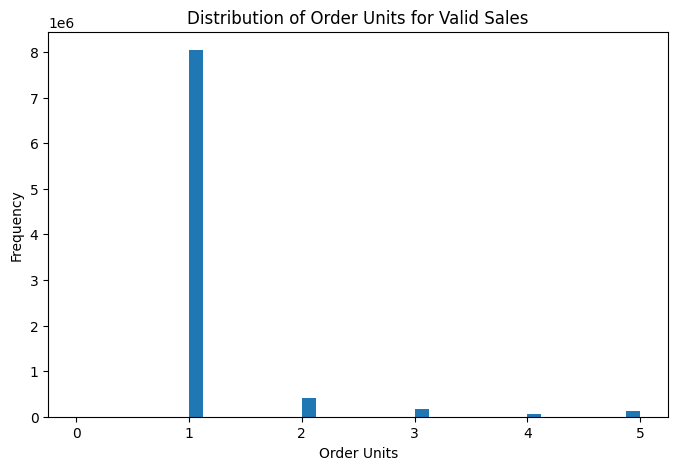

In [36]:
import matplotlib.pyplot as plt
units_plot = valid_sales[
    valid_sales["order_units"]
    <= valid_sales["order_units"].quantile(0.99)
]["order_units"]

plt.figure(figsize=(8, 5))
plt.hist(units_plot, bins=40)

plt.title("Distribution of Order Units for Valid Sales")
plt.xlabel("Order Units")
plt.ylabel("Frequency")
plt.show()

### Observation

Most valid sales contain a very small number of units.

- The median order quantity is 1 unit.
- 95% of valid sales contain no more than 2 units.
- 99% contain no more than 5 units.
- A small number of very large orders exist, with the maximum reaching 1,600 units.

This shows that order quantity is highly right-skewed, with most transactions being small purchases and only a few very large orders.

For later modeling, these extreme large orders may need special treatment or aggregation so that they do not dominate the price sensitivity model.

## 2.4 Price Definition

### Question

For the initial analysis, we define:

**Unit Price = Revenue / Order Units**

This provides an estimated transaction-level selling price.

Only valid completed sales with positive `order_units` are used to avoid invalid division and non-sales records.

In [38]:
import numpy as np
valid_sales["unit_price"] = np.where(
    valid_sales["order_units"] > 0,
    valid_sales["revenue"] / valid_sales["order_units"],
    np.nan
)

display(
    valid_sales["unit_price"]
    .describe(
        percentiles=[0.01, 0.05, 0.50, 0.95, 0.99]
    )
)

count    8.864796e+06
mean     3.000547e+02
std      6.083369e+02
min      0.000000e+00
1%       0.000000e+00
5%       0.000000e+00
50%      2.200000e+01
95%      1.602760e+03
99%      2.599990e+03
max      9.949620e+04
Name: unit_price, dtype: float64

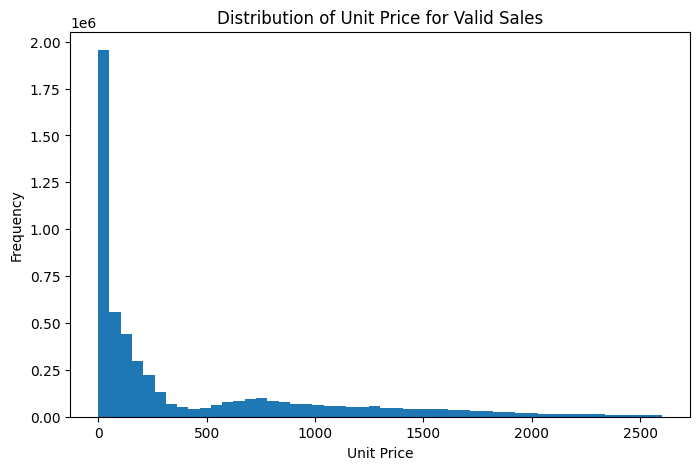

In [39]:
price_plot = valid_sales[
    (valid_sales["unit_price"] > 0) &
    (
        valid_sales["unit_price"]
        <= valid_sales["unit_price"].quantile(0.99)
    )
]["unit_price"]

plt.figure(figsize=(8, 5))
plt.hist(price_plot, bins=50)

plt.title("Distribution of Unit Price for Valid Sales")
plt.xlabel("Unit Price")
plt.ylabel("Frequency")
plt.show()

In [40]:
price_tier_check = (
    valid_sales.groupby("price_tier")
    .agg(
        count=("unit_price", "size"),
        median_unit_price=("unit_price", "median"),
        avg_unit_price=("unit_price", "mean")
    )
    .sort_values("median_unit_price")
)

display(price_tier_check)

,count,median_unit_price,avg_unit_price
price_tier,,,
$0 - $299,6887741,0.01,39.961584
$300 - $499,64839,376.50,382.858559
$300 - $499,141431,386.12,389.346983
$500 - $699,219236,608.99,609.062580
$500 - $699,67995,625.39,617.602286
$700 - $999,333429,829.00,836.464779
$700 - $999,139296,849.00,849.831789
$1000 - $1299,309198,1144.99,1146.800505
$1300 - $1499,175028,1394.55,1395.869489


### Observation

The constructed `unit_price = revenue / order_units` appears to be a reasonable continuous measure of transaction-level price.

The unit price distribution is strongly right-skewed: most transactions occur at relatively low price levels, while a small number of high-priced products create a long right tail.

The median unit prices within each `price_tier` generally fall within the expected price ranges, which provides a useful validation of the constructed price variable.

Therefore, `unit_price` can be used as the primary continuous price variable for the initial price sensitivity analysis.

## 2.5 Key Business Segment Analysis

### Question

Do pricing and business outcomes differ across major product types, customer segments, and sales channels?

These variables are important because price sensitivity may vary across different products and customer groups.

We compare:

- Average unit price
- Total units
- Total revenue
- Total margin

This helps identify the most important contextual variables for the later machine learning model.

In [41]:
product_summary = (
    valid_sales.groupby("product_type")
    .agg(
        transactions=("product_type", "size"),
        avg_unit_price=("unit_price", "mean"),
        median_unit_price=("unit_price", "median"),
        total_units=("order_units", "sum"),
        total_revenue=("revenue", "sum"),
        total_margin=("margin", "sum")
    )
    .sort_values("total_revenue", ascending=False)
)

display(product_summary)

,transactions,avg_unit_price,median_unit_price,total_units,total_revenue,total_margin
product_type,,,,,,
Notebook,1347677,1141.985642,1010.210,1789482.0,1.984953e+09,3.345934e+08
Workstations,293742,1840.925086,1637.465,406034.0,7.057495e+08,1.352149e+08
Desktop,211538,1026.602498,844.320,297635.0,2.831121e+08,2.870224e+07
Options,1724281,69.503973,30.620,2317257.0,1.657518e+08,3.240560e+07
Services,1571983,83.085722,46.160,2004793.0,1.620300e+08,1.098317e+08
Visuals,215535,198.014034,166.170,386122.0,7.287710e+07,1.346990e+07
Tablets,260294,161.889296,134.990,348324.0,5.411623e+07,7.311119e+06
Servers,6146,2249.623012,1188.390,6973.0,1.511229e+07,5.365383e+06
Handheld,11942,748.298605,749.990,13188.0,9.928290e+06,1.538969e+06


In [42]:
segment_summary = (
    valid_sales.groupby("segment")
    .agg(
        transactions=("segment", "size"),
        avg_unit_price=("unit_price", "mean"),
        median_unit_price=("unit_price", "median"),
        total_units=("order_units", "sum"),
        total_revenue=("revenue", "sum"),
        total_margin=("margin", "sum")
    )
    .sort_values("total_revenue", ascending=False)
)

display(segment_summary)

,transactions,avg_unit_price,median_unit_price,total_units,total_revenue,total_margin
segment,,,,,,
Enterprise,6399816,279.321847,0.01,7753907.0,2.465138e+09,5.973677e+08
Personal,2097995,400.721400,109.00,2566146.0,9.530769e+08,7.858420e+07
Partner Channel,366170,85.176222,34.99,470964.0,4.004028e+07,-7.750508e+06


In [43]:
channel_summary = (
    valid_sales.groupby("sales_channel")
    .agg(
        transactions=("sales_channel", "size"),
        avg_unit_price=("unit_price", "mean"),
        median_unit_price=("unit_price", "median"),
        total_units=("order_units", "sum"),
        total_revenue=("revenue", "sum"),
        total_margin=("margin", "sum")
    )
    .sort_values("total_revenue", ascending=False)
)

display(channel_summary)

,transactions,avg_unit_price,median_unit_price,total_units,total_revenue,total_margin
sales_channel,,,,,,
Direct,8636561,300.419749,22.000,10425336.0,3.338341e+09,6.754788e+08
Marketplace,228100,286.188072,27.720,366613.0,1.204090e+08,-7.215376e+06
Commercial Employee Program,96,361.821875,9.955,353.0,1.244417e+05,3.633016e+04
Clearance,23,393.452174,186.010,28.0,1.256742e+04,-2.780506e+03
Consumer Program,17,444.352353,116.390,32.0,1.033068e+04,3.017040e+03


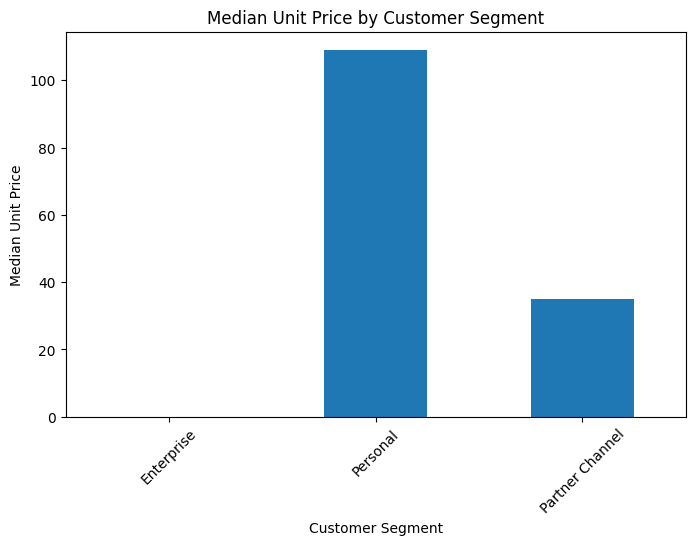

In [44]:
segment_summary["median_unit_price"].plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Median Unit Price by Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Median Unit Price")
plt.xticks(rotation=45)
plt.show()

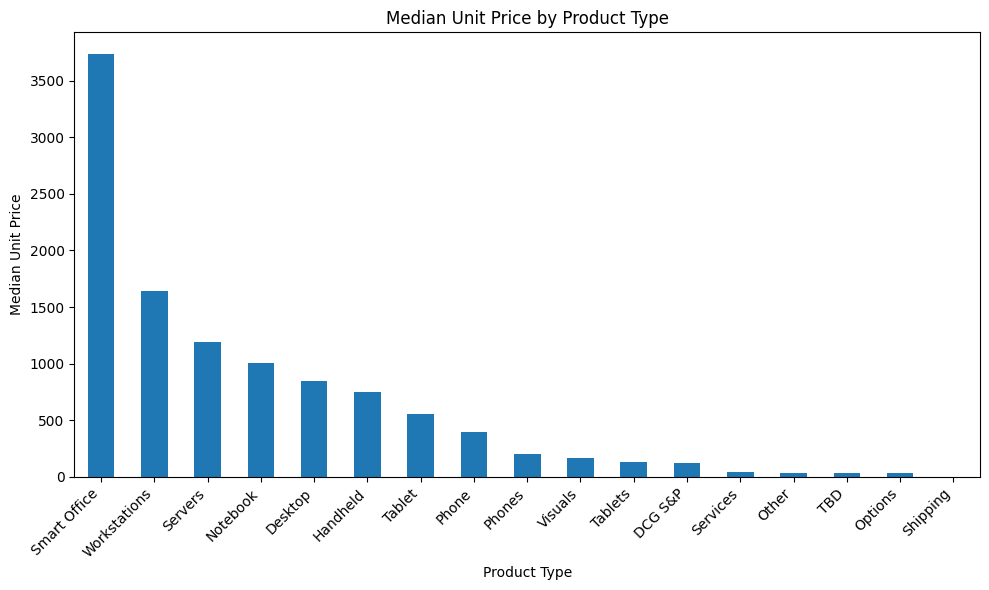

In [45]:
product_price = (
    valid_sales.groupby("product_type")["unit_price"]
    .median()
    .sort_values(ascending=False)
)

plt.figure(figsize=(10, 6))

product_price.plot(kind="bar")

plt.title("Median Unit Price by Product Type")
plt.xlabel("Product Type")
plt.ylabel("Median Unit Price")
plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()

### Observation

Product type shows substantial differences in typical unit price. For example, notebooks, workstations, desktops, and servers operate at much higher price levels than options, services, and shipping-related records.

This indicates that product characteristics are an important source of price variation and should be controlled for in the later price sensitivity model.

Customer segment and sales channel also show differences in price and business outcomes. However, these differences may partly reflect different product mixes across customer groups and channels.

Therefore, `product_type`, `segment`, and `sales_channel` should be considered as contextual variables, with `product_type` being especially important for the pricing model.

## 2.6 Time Trend and Preliminary Price-Demand Relationship

### Question

How do sales change over time, and is there an initial relationship between price and demand?

Time is an important contextual factor because demand may change due to seasonality, promotions, and product lifecycle effects.

We first examine weekly sales trends and then conduct a preliminary analysis of the relationship between average price and total units sold.

This analysis is exploratory and does not represent causal price elasticity.

In [46]:
weekly_summary = (
    valid_sales.groupby("week_begin")
    .agg(
        total_units=("order_units", "sum"),
        total_revenue=("revenue", "sum"),
        avg_unit_price=("unit_price", "mean")
    )
    .reset_index()
    .sort_values("week_begin")
)

display(weekly_summary.head())

,week_begin,total_units,total_revenue,avg_unit_price
0,2023-03-27,3815.0,941791.29,239.448512
1,2023-04-03,33696.0,10480241.27,261.400539
2,2023-04-10,43298.0,15452900.86,328.499143
3,2023-04-17,48595.0,15558265.43,295.299823
4,2023-04-24,53716.0,17580027.11,277.753042


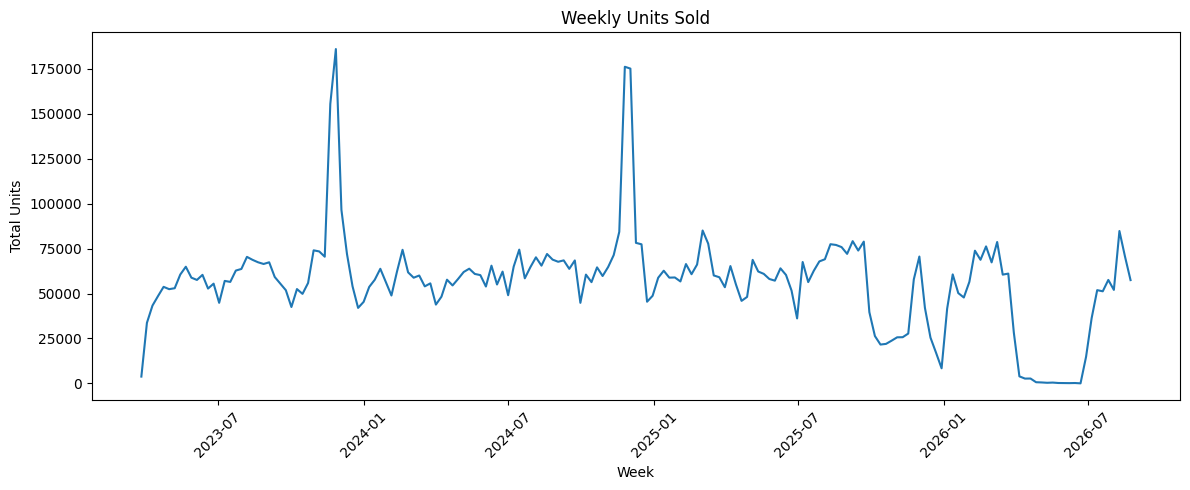

In [47]:
plt.figure(figsize=(12, 5))

plt.plot(
    weekly_summary["week_begin"],
    weekly_summary["total_units"]
)

plt.title("Weekly Units Sold")
plt.xlabel("Week")
plt.ylabel("Total Units")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [51]:
price_demand = (
    valid_sales[
        valid_sales["unit_price"] > 0
    ]
    .groupby(
        ["week_begin", "product_type"]
    )
    .agg(
        avg_price=("unit_price", "mean"),
        total_units=("order_units", "sum"),
        transaction_count=("order_units", "size")
    )
    .reset_index()
)

display(price_demand.head())

,week_begin,product_type,avg_price,total_units,transaction_count
0,2023-03-27,Desktop,1185.892818,70.0,66
1,2023-03-27,Notebook,1175.400612,422.0,379
2,2023-03-27,Options,55.846273,806.0,662
3,2023-03-27,Services,63.985474,581.0,560
4,2023-03-27,Shipping,41.530000,13.0,13


In [52]:
price_demand[
    ["avg_price", "total_units"]
].corr()

,avg_price,total_units
avg_price,1.000000,-0.153586
total_units,-0.153586,1.000000


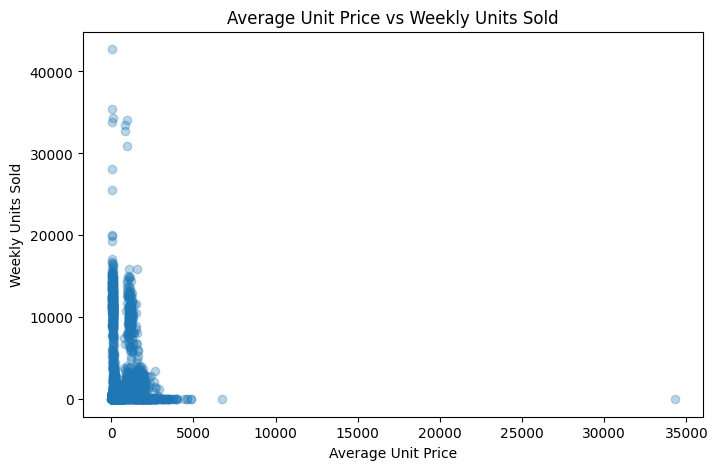

In [53]:
plt.figure(figsize=(8, 5))

plt.scatter(
    price_demand["avg_price"],
    price_demand["total_units"],
    alpha=0.3
)

plt.title("Average Unit Price vs Weekly Units Sold")
plt.xlabel("Average Unit Price")
plt.ylabel("Weekly Units Sold")

plt.show()

### Observation

The preliminary analysis shows a weak negative correlation (`-0.154`) between average unit price and weekly units sold.

This direction is consistent with the general expectation that higher prices may be associated with lower demand. However, the relationship is weak and should not be interpreted as price elasticity.

The scatter plot also shows substantial differences across product types in both price level and sales volume. Therefore, price sensitivity should be analyzed within comparable product groups rather than across all product types together.

The machine learning model should control for product characteristics and other contextual factors before estimating the effect of price on demand.

In [54]:
notebook_pd = (
    valid_sales[
        (valid_sales["product_type"] == "Notebook") &
        (valid_sales["unit_price"] > 0)
    ]
    .groupby("week_begin")
    .agg(
        avg_price=("unit_price", "mean"),
        total_units=("order_units", "sum"),
        transaction_count=("order_units", "size")
    )
    .reset_index()
    .sort_values("week_begin")
)

display(notebook_pd.head())

,week_begin,avg_price,total_units,transaction_count
0,2023-03-27,1175.400612,422.0,379
1,2023-04-03,1219.284801,3966.0,3162
2,2023-04-10,1318.108151,5785.0,4462
3,2023-04-17,1171.625204,8250.0,6119
4,2023-04-24,1090.690633,9573.0,6886


In [55]:
notebook_corr = (
    notebook_pd[
        ["avg_price", "total_units"]
    ]
    .corr()
)

display(notebook_corr)

,avg_price,total_units
avg_price,1.000000,-0.270398
total_units,-0.270398,1.000000


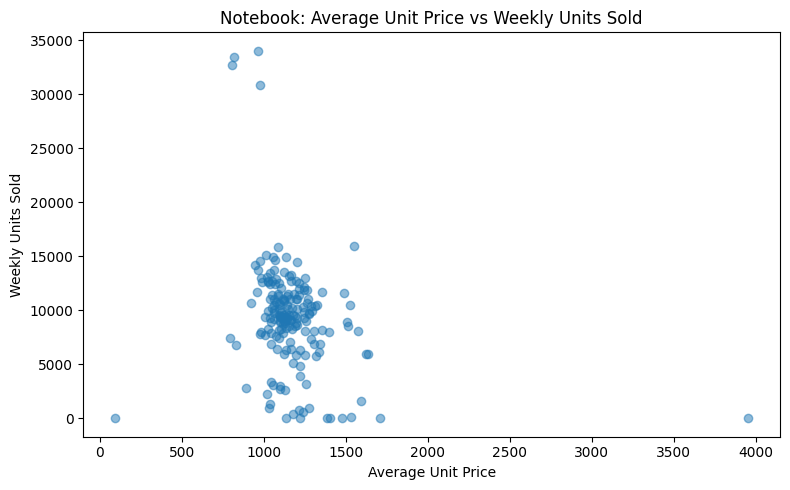

In [56]:
plt.figure(figsize=(8, 5))

plt.scatter(
    notebook_pd["avg_price"],
    notebook_pd["total_units"],
    alpha=0.5
)

plt.title("Notebook: Average Unit Price vs Weekly Units Sold")
plt.xlabel("Average Unit Price")
plt.ylabel("Weekly Units Sold")

plt.tight_layout()
plt.show()

### Observation

Within the Notebook product category, average unit price and weekly units sold show a moderate negative correlation of approximately **-0.27**.

This relationship is stronger than the overall correlation observed across all product types, suggesting that price-demand patterns become clearer when comparisons are made within a more comparable product group.

However, several unusual weeks with extremely low or high sales volumes are still present. These may reflect incomplete data coverage, promotions, product-mix changes, seasonality, or other business factors.

Therefore, the negative relationship provides preliminary evidence of price sensitivity, but a machine learning model should control for time, product model, customer segment, sales channel, and other contextual factors before estimating the impact of price on demand.